> **Portfolio summary:** GARCH(1,1) vs GJR-GARCH for the FTSE 100, S&P 500 and Nikkei 225, with a rolling forecast horserace (group project).
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

# Volatility Modelling Across Financial Indices
## GARCH(1,1) vs GJR-GARCH(1,1)

We select three major equity market indices:
- **S&P 500** (^GSPC) - US large-cap
- **FTSE 100** (^FTSE) - UK large-cap
- **Nikkei 225** (^N225) - Japanese large-cap

Data: Daily closing prices from 2018-01-01 to 2023-12-31 (6 years), covering COVID-19 and the 2022 rate-hiking cycle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from arch import arch_model
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')

plt.rc('font', size=14)
plt.rc('axes', titlesize=18, labelsize=16)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)

## 1. Data Loading & Returns

In [2]:
tickers = {'^GSPC': 'S&P 500', '^FTSE': 'FTSE 100', '^N225': 'Nikkei 225'}
prices = yf.download(list(tickers.keys()), start='2018-01-01', end='2023-12-31')['Close']
prices.columns = [tickers[c] for c in prices.columns]
prices = prices.dropna()

# Arithmetic returns
returns = prices.pct_change().dropna()

print(f"Price observations: {len(prices)}")
print(f"Return observations: {len(returns)}")
print(f"\nDate range: {returns.index[0].date()} to {returns.index[-1].date()}")
print(f"\nReturn summary statistics:")
print(returns.describe().round(6))

Price observations: 1387
Return observations: 1386

Date range: 2018-01-05 to 2023-12-29

Return summary statistics:
          FTSE 100      S&P 500   Nikkei 225
count  1386.000000  1386.000000  1386.000000
mean      0.000065     0.000495     0.000331
std       0.011064     0.013410     0.012383
min      -0.108738    -0.119841    -0.060808
25%      -0.004651    -0.004988    -0.006183
50%       0.000686     0.000893     0.000773
75%       0.005333     0.007213     0.006990
max       0.090530     0.093828     0.080381

In [3]:
# Annualised volatility to identify most volatile index
ann_vol = returns.std() * np.sqrt(252)
print("Annualised volatility (full sample):")
for name, vol in ann_vol.items():
    print(f"  {name}: {vol:.4f} ({vol*100:.2f}%)")

most_volatile = ann_vol.idxmax()
print(f"\nMost volatile index: {most_volatile}")

Annualised volatility (full sample):
  FTSE 100: 0.1756 (17.56%)
  S&P 500: 0.2129 (21.29%)
  Nikkei 225: 0.1966 (19.66%)

Most volatile index: S&P 500

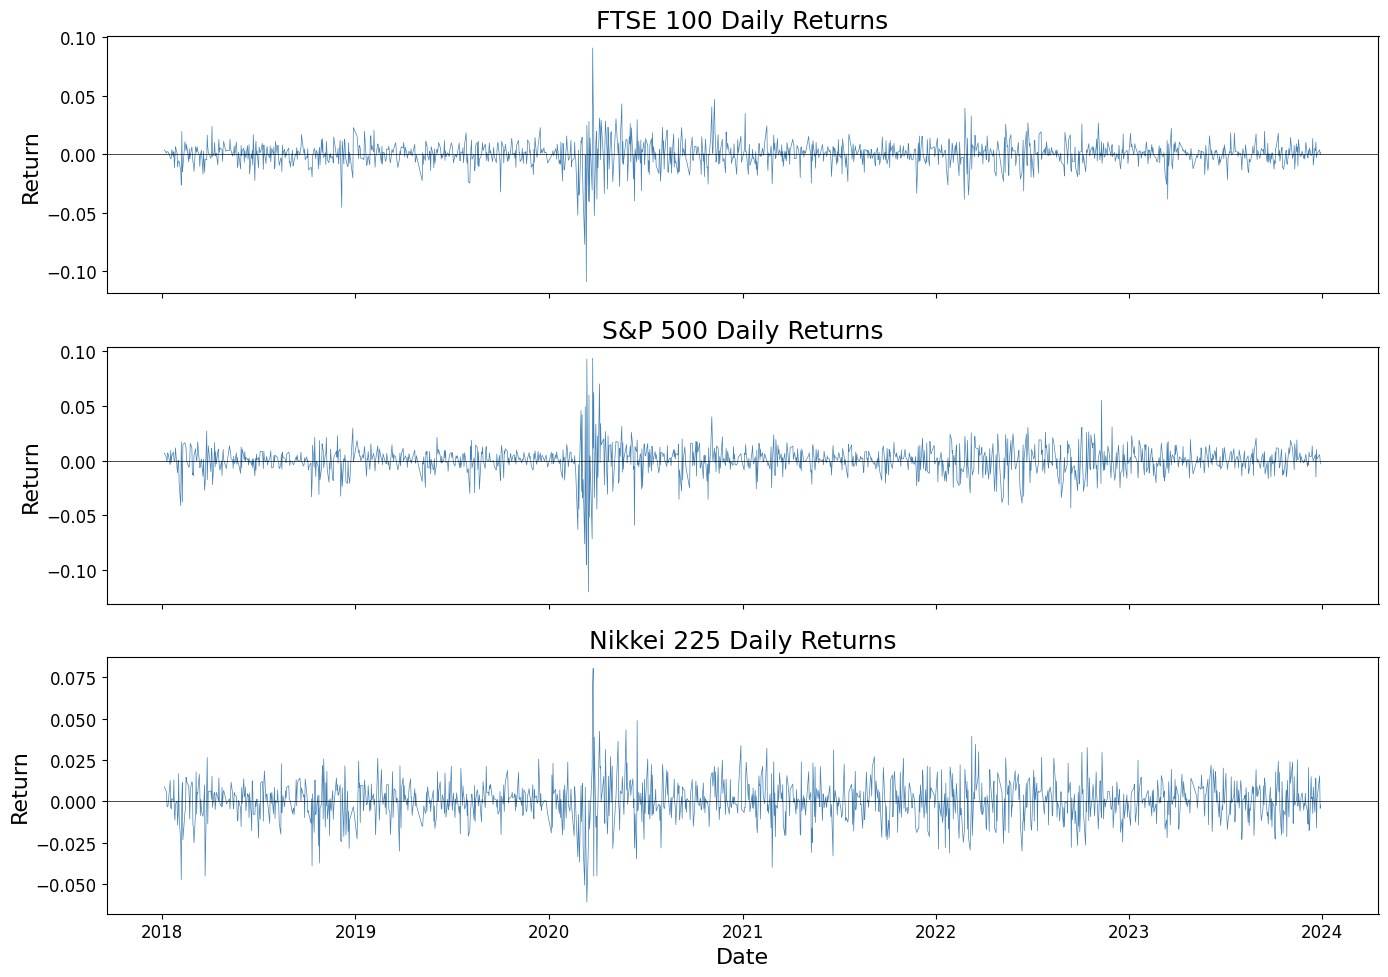

In [4]:
# Plot return series
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col in zip(axes, returns.columns):
    ax.plot(returns.index, returns[col], linewidth=0.5, color='steelblue')
    ax.set_title(f'{col} Daily Returns')
    ax.set_ylabel('Return')
    ax.axhline(0, color='black', linewidth=0.5)
axes[-1].set_xlabel('Date')
fig.tight_layout()
fig.savefig('returns_series.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Rolling Window Volatility

Before fitting parametric models, we compute rolling standard deviations with 60-day and 120-day windows to visualise volatility clustering.

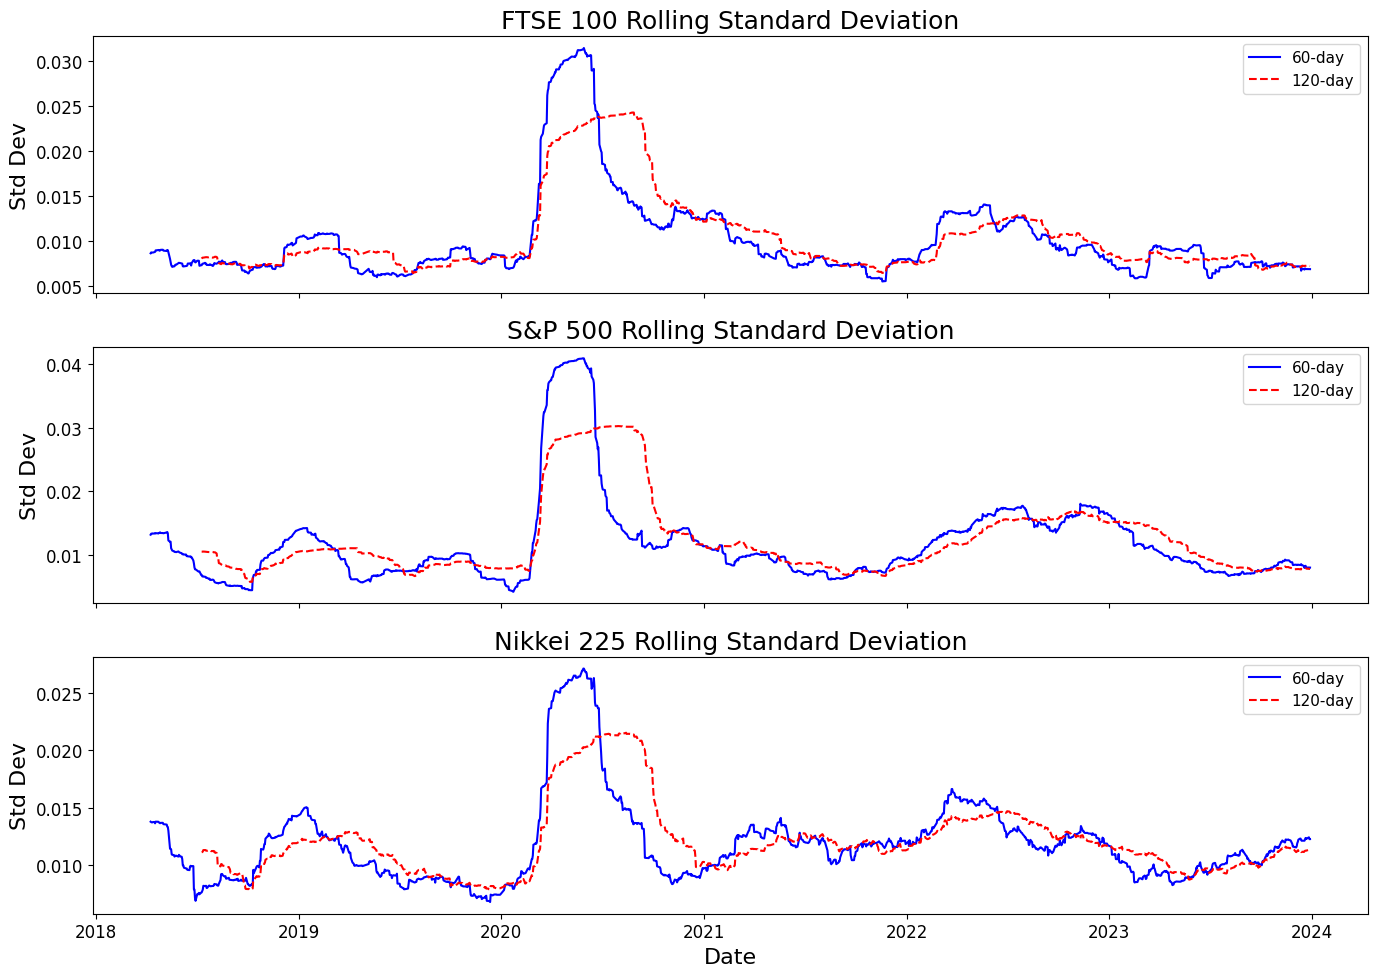

In [5]:
s_60 = returns.rolling(60).std(ddof=1)
s_120 = returns.rolling(120).std(ddof=1)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col in zip(axes, returns.columns):
    ax.plot(s_60.index, s_60[col], 'b-', linewidth=1.5, label='60-day')
    ax.plot(s_120.index, s_120[col], 'r--', linewidth=1.5, label='120-day')
    ax.set_title(f'{col} Rolling Standard Deviation')
    ax.set_ylabel('Std Dev')
    ax.legend(fontsize=11)
axes[-1].set_xlabel('Date')
fig.tight_layout()
fig.savefig('rolling_sd.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. GARCH(1,1) Estimation

We fit GARCH(1,1) to each index using a zero-mean specification (standard for daily returns):

$$\sigma_t^2 = \omega + \alpha\, a_{t-1}^2 + \beta\, \sigma_{t-1}^2$$

Returns are scaled by 100 to improve optimiser convergence.

In [6]:
garch_results = {}
for col in returns.columns:
    r_scaled = returns[col] * 100
    model = arch_model(r_scaled, mean='Zero', vol='GARCH', p=1, q=1, rescale=False)
    res = model.fit(disp='off')
    garch_results[col] = res
    print(f"\n{'='*60}")
    print(f"{col} - GARCH(1,1)")
    print(f"{'='*60}")
    print(res.summary())


FTSE 100 - GARCH(1,1)
                       Zero Mean - GARCH Model Results                        
Dep. Variable:               FTSE 100   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.001
Vol Model:                      GARCH   Log-Likelihood:               -1874.11
Distribution:                  Normal   AIC:                           3754.23
Method:            Maximum Likelihood   BIC:                           3769.93
                                        No. Observations:                 1386
Date:                Tue, May 19 2026   Df Residuals:                     1386
Time:                        22:52:18   Df Model:                            0
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.0779  1.976e-02      3.9

In [7]:
# Parameter comparison table
param_table = pd.DataFrame(
    {col: res.params for col, res in garch_results.items()}
).T
param_table['alpha+beta'] = param_table['alpha[1]'] + param_table['beta[1]']
param_table['V_L'] = param_table['omega'] / (1 - param_table['alpha+beta'])
param_table['V_L_annual'] = np.sqrt(param_table['V_L'] * 252) / 100
print("GARCH(1,1) Parameter Summary:")
print(param_table.round(6))

GARCH(1,1) Parameter Summary:
               omega  alpha[1]   beta[1]  alpha+beta       V_L  V_L_annual
FTSE 100    0.077874  0.159857  0.769593    0.929451  1.103821    0.166782
S&P 500     0.051047  0.172123  0.800605    0.972728  1.871778    0.217184
Nikkei 225  0.062883  0.076445  0.880507    0.956952  1.460750    0.191862

## 4. GJR-GARCH(1,1) Estimation

The GJR-GARCH model (Glosten, Jagannathan & Runkle, 1993) adds a leverage term to capture the asymmetric impact of negative vs positive shocks:

$$\sigma_t^2 = \omega + \alpha\, a_{t-1}^2 + \gamma\, a_{t-1}^2 \cdot \mathbf{1}_{[a_{t-1}<0]} + \beta\, \sigma_{t-1}^2$$

If $\gamma > 0$, negative returns increase volatility more than positive returns of the same size.

In [8]:
gjr_results = {}
for col in returns.columns:
    r_scaled = returns[col] * 100
    model = arch_model(r_scaled, mean='Zero', vol='GARCH', p=1, o=1, q=1, rescale=False)
    res = model.fit(disp='off')
    gjr_results[col] = res
    print(f"\n{'='*60}")
    print(f"{col} - GJR-GARCH(1,1)")
    print(f"{'='*60}")
    print(res.summary())


FTSE 100 - GJR-GARCH(1,1)
                     Zero Mean - GJR-GARCH Model Results                      
Dep. Variable:               FTSE 100   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.001
Vol Model:                  GJR-GARCH   Log-Likelihood:               -1855.65
Distribution:                  Normal   AIC:                           3719.29
Method:            Maximum Likelihood   BIC:                           3740.23
                                        No. Observations:                 1386
Date:                Tue, May 19 2026   Df Residuals:                     1386
Time:                        22:52:18   Df Model:                            0
                               Volatility Model                              
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
omega          0.0717  1.930

In [9]:
# GJR parameter comparison
gjr_table = pd.DataFrame(
    {col: res.params for col, res in gjr_results.items()}
).T
gjr_table['leverage_ratio'] = (gjr_table['alpha[1]'] + gjr_table['gamma[1]']) / gjr_table['alpha[1]']
print("GJR-GARCH(1,1) Parameter Summary:")
print(gjr_table.round(6))

GJR-GARCH(1,1) Parameter Summary:
               omega  alpha[1]  gamma[1]   beta[1]  leverage_ratio
FTSE 100    0.071741  0.022094  0.212379  0.800869       10.612648
S&P 500     0.059770  0.060199  0.285923  0.778105        5.749606
Nikkei 225  0.101694  0.006356  0.185556  0.835034       30.192824

## 5. Exploratory Analysis on Most Volatile Index

We now perform detailed diagnostics on the index with the largest annualised volatility.

In [10]:
mv = most_volatile
r_mv = returns[mv] * 100
res_garch = garch_results[mv]
res_gjr = gjr_results[mv]

print(f"Exploratory analysis: {mv}")
print(f"Observations: {len(r_mv)}")
print(f"Annualised vol: {ann_vol[mv]*100:.2f}%")

Exploratory analysis: S&P 500
Observations: 1386
Annualised vol: 21.29%

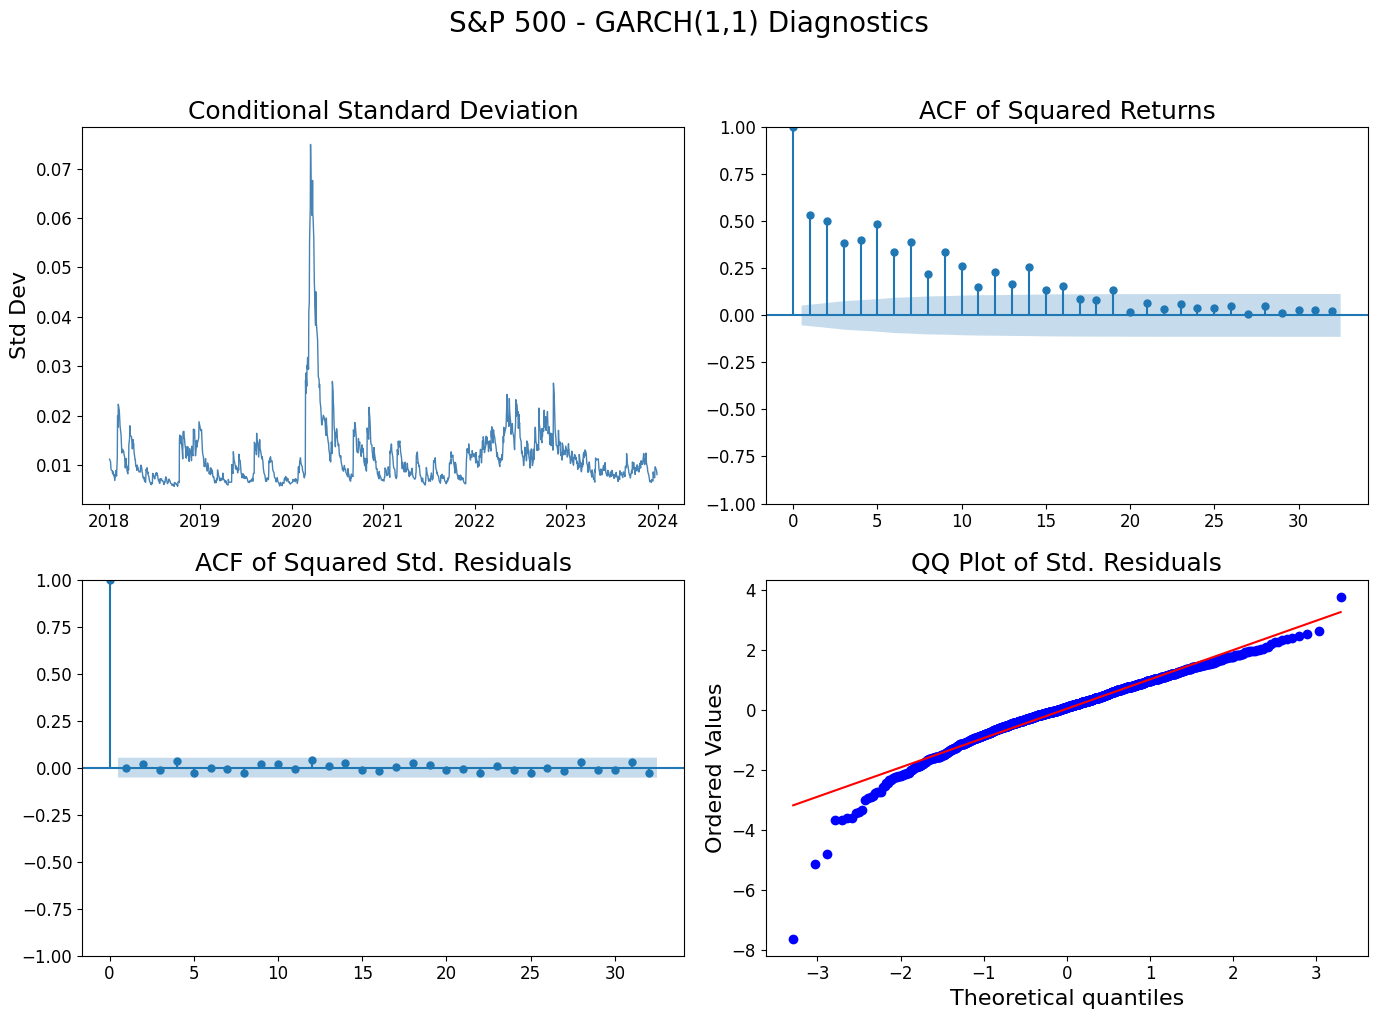

In [11]:
# Extract conditional volatility from both models
cond_vol_garch = res_garch.conditional_volatility / 100
cond_vol_gjr = res_gjr.conditional_volatility / 100

# Standardised residuals
std_resid_garch = res_garch.std_resid
std_resid_gjr = res_gjr.std_resid

# Diagnostic panel for GARCH(1,1)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'{mv} - GARCH(1,1) Diagnostics', fontsize=20, y=1.02)

axs[0,0].plot(cond_vol_garch.index, cond_vol_garch, color='steelblue', linewidth=1)
axs[0,0].set_title('Conditional Standard Deviation')
axs[0,0].set_ylabel('Std Dev')

plot_acf(r_mv**2, alpha=0.05, ax=axs[0,1], title=f'ACF of Squared Returns')

plot_acf(std_resid_garch**2, alpha=0.05, ax=axs[1,0], title='ACF of Squared Std. Residuals')

stats.probplot(std_resid_garch, dist='norm', plot=axs[1,1])
axs[1,1].set_title('QQ Plot of Std. Residuals')

fig.tight_layout()
fig.savefig(f'diagnostics_garch_{mv.replace(" ", "_")}.png', dpi=200, bbox_inches='tight')
plt.show()

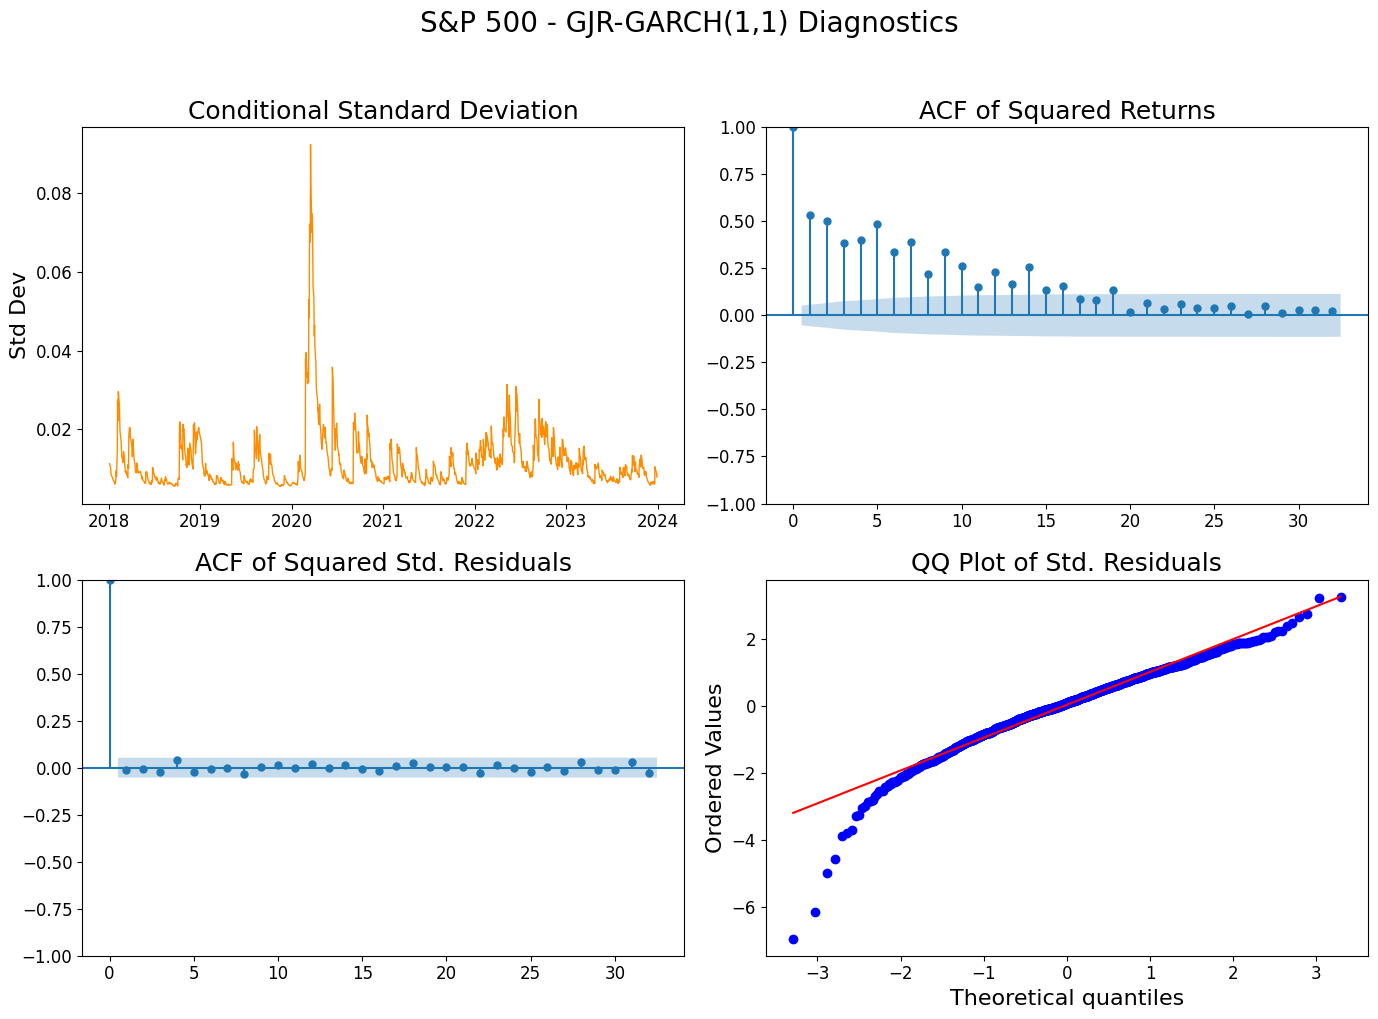

In [12]:
# Diagnostic panel for GJR-GARCH(1,1)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'{mv} - GJR-GARCH(1,1) Diagnostics', fontsize=20, y=1.02)

axs[0,0].plot(cond_vol_gjr.index, cond_vol_gjr, color='darkorange', linewidth=1)
axs[0,0].set_title('Conditional Standard Deviation')
axs[0,0].set_ylabel('Std Dev')

plot_acf(r_mv**2, alpha=0.05, ax=axs[0,1], title=f'ACF of Squared Returns')

plot_acf(std_resid_gjr**2, alpha=0.05, ax=axs[1,0], title='ACF of Squared Std. Residuals')

stats.probplot(std_resid_gjr, dist='norm', plot=axs[1,1])
axs[1,1].set_title('QQ Plot of Std. Residuals')

fig.tight_layout()
fig.savefig(f'diagnostics_gjr_{mv.replace(" ", "_")}.png', dpi=200, bbox_inches='tight')
plt.show()

In [13]:
# Ljung-Box tests
print(f"Ljung-Box Tests for {mv}")
print("="*60)

print("\nSquared returns (lags=15):")
lb = acorr_ljungbox(r_mv**2, lags=[15])
print(f"  Q(15) = {lb['lb_stat'].values[0]:.4f}, p = {lb['lb_pvalue'].values[0]:.6f}")

print("\nGARCH(1,1) squared std residuals (lags=15, model_df=3):")
lb = acorr_ljungbox(np.array(std_resid_garch)**2, lags=[15], model_df=3)
print(f"  Q(12) = {lb['lb_stat'].values[0]:.4f}, p = {lb['lb_pvalue'].values[0]:.6f}")

print("\nGJR-GARCH(1,1) squared std residuals (lags=15, model_df=4):")
lb = acorr_ljungbox(np.array(std_resid_gjr)**2, lags=[15], model_df=4)
print(f"  Q(11) = {lb['lb_stat'].values[0]:.4f}, p = {lb['lb_pvalue'].values[0]:.6f}")

Ljung-Box Tests for S&P 500

Squared returns (lags=15):
  Q(15) = 2456.6918, p = 0.000000

GARCH(1,1) squared std residuals (lags=15, model_df=3):
  Q(12) = 9.4072, p = 0.667815

GJR-GARCH(1,1) squared std residuals (lags=15, model_df=4):
  Q(11) = 6.8428, p = 0.811669

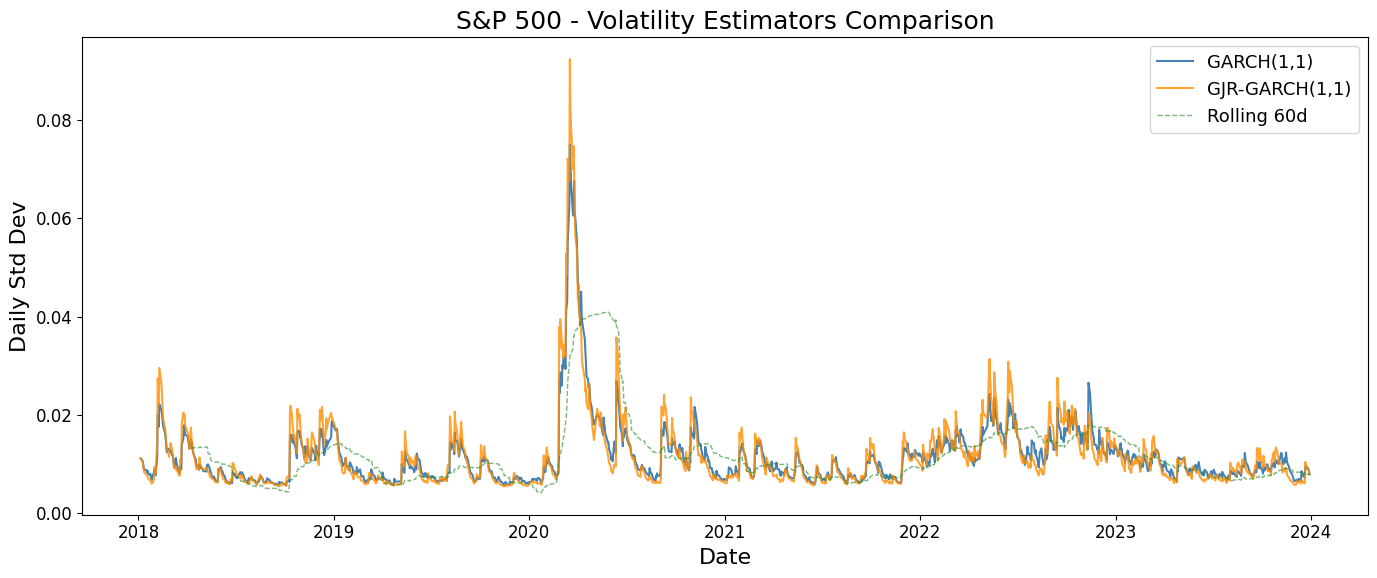

In [14]:
# Compare conditional volatilities from both models
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(cond_vol_garch.index, cond_vol_garch, color='steelblue', linewidth=1.5, label='GARCH(1,1)')
ax.plot(cond_vol_gjr.index, cond_vol_gjr, color='darkorange', linewidth=1.5, label='GJR-GARCH(1,1)', alpha=0.8)
ax.plot(s_60[mv].index, s_60[mv], color='forestgreen', linewidth=1, linestyle='--', label='Rolling 60d', alpha=0.6)
ax.set_title(f'{mv} - Volatility Estimators Comparison', fontsize=18)
ax.set_ylabel('Daily Std Dev')
ax.set_xlabel('Date')
ax.legend(fontsize=13)
fig.tight_layout()
fig.savefig(f'vol_comparison_{mv.replace(" ", "_")}.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Model Comparison: Information Criteria

In [15]:
# AIC/BIC comparison
comparison = []
for col in returns.columns:
    comparison.append({
        'Index': col,
        'GARCH AIC': garch_results[col].aic,
        'GJR AIC': gjr_results[col].aic,
        'GARCH BIC': garch_results[col].bic,
        'GJR BIC': gjr_results[col].bic,
        'GARCH LogLik': garch_results[col].loglikelihood,
        'GJR LogLik': gjr_results[col].loglikelihood
    })
comp_df = pd.DataFrame(comparison).set_index('Index')
print("Model Comparison (lower AIC/BIC = better):")
print(comp_df.round(2))

Model Comparison (lower AIC/BIC = better):
            GARCH AIC  GJR AIC  GARCH BIC  GJR BIC  GARCH LogLik  GJR LogLik
Index                                                                       
FTSE 100      3754.23  3719.29    3769.93  3740.23      -1874.11    -1855.65
S&P 500       4060.20  4008.71    4075.90  4029.65      -2027.10    -2000.36
Nikkei 225    4355.37  4310.29    4371.07  4331.23      -2174.69    -2151.15

## 7. Horserace: Rolling 10-Day Ahead Average Volatility Forecast

We compare GARCH(1,1) and GJR-GARCH(1,1) using rolling 10-day ahead average variance forecasts.

**GARCH forecast** (mean-reversion formula):
$$E_t\left[\frac{1}{T}\sum_{h=1}^{T}\sigma_{t+h}^2\right] = V_L + \frac{1 - e^{-T\gamma}}{T\gamma}(\sigma_t^2 - V_L)$$

**Realized variance** (target):
$$\bar{\sigma}^2_{\text{realized}} = \frac{1}{10}\sum_{h=1}^{10} r_{t+h}^2$$

We evaluate using RMSE and MAE.

In [16]:
T_horizon = 10

def rolling_forecast_horserace(r_series, garch_res, gjr_res, T=10):
    """
    Produce rolling T-day ahead average variance forecasts
    from GARCH(1,1) and GJR-GARCH(1,1), compared to realized variance.
    """
    n = len(r_series)
    
    # GARCH(1,1) conditional variance path
    garch_cv = np.array(garch_res.conditional_volatility)**2
    omega_g, alpha_g, beta_g = garch_res.params['omega'], garch_res.params['alpha[1]'], garch_res.params['beta[1]']
    VL_g = omega_g / (1 - alpha_g - beta_g)
    gamma_g = -np.log(alpha_g + beta_g)
    
    # GJR-GARCH(1,1) conditional variance path
    gjr_cv = np.array(gjr_res.conditional_volatility)**2
    omega_j = gjr_res.params['omega']
    alpha_j = gjr_res.params['alpha[1]']
    gamma_j_param = gjr_res.params['gamma[1]']
    beta_j = gjr_res.params['beta[1]']
    persistence_j = alpha_j + beta_j + gamma_j_param * 0.5
    VL_j = omega_j / (1 - persistence_j)
    gamma_j_speed = -np.log(persistence_j)
    
    r_arr = np.array(r_series)
    
    forecast_garch = np.full(n, np.nan)
    forecast_gjr = np.full(n, np.nan)
    realized = np.full(n, np.nan)
    
    for t in range(0, n - T):
        # GARCH forecast
        sig2_g = garch_cv[t]
        forecast_garch[t] = VL_g + (1 - np.exp(-T * gamma_g)) / (T * gamma_g) * (sig2_g - VL_g)
        
        # GJR forecast
        sig2_j = gjr_cv[t]
        forecast_gjr[t] = VL_j + (1 - np.exp(-T * gamma_j_speed)) / (T * gamma_j_speed) * (sig2_j - VL_j)
        
        # Realized
        realized[t] = np.mean(r_arr[t+1:t+1+T]**2)
    
    return forecast_garch, forecast_gjr, realized


# Run horserace for each index
horserace_results = {}
for col in returns.columns:
    r_scaled = returns[col] * 100
    fg, fj, real = rolling_forecast_horserace(
        r_scaled, garch_results[col], gjr_results[col], T=T_horizon
    )
    horserace_results[col] = (fg, fj, real)

In [17]:
# Evaluation metrics
print(f"Rolling {T_horizon}-Day Ahead Average Variance Forecast Evaluation")
print("="*70)

eval_rows = []
for col in returns.columns:
    fg, fj, real = horserace_results[col]
    valid = ~np.isnan(fg) & ~np.isnan(real)
    fg_v, fj_v, real_v = fg[valid], fj[valid], real[valid]
    
    rmse_g = np.sqrt(np.mean((fg_v - real_v)**2))
    rmse_j = np.sqrt(np.mean((fj_v - real_v)**2))
    mae_g = np.mean(np.abs(fg_v - real_v))
    mae_j = np.mean(np.abs(fj_v - real_v))
    
    eval_rows.append({
        'Index': col,
        'GARCH RMSE': rmse_g,
        'GJR RMSE': rmse_j,
        'GARCH MAE': mae_g,
        'GJR MAE': mae_j,
        'Winner (RMSE)': 'GJR' if rmse_j < rmse_g else 'GARCH',
        'Winner (MAE)': 'GJR' if mae_j < mae_g else 'GARCH'
    })
    
    print(f"\n{col}:")
    print(f"  GARCH(1,1):     RMSE = {rmse_g:.6f}  |  MAE = {mae_g:.6f}")
    print(f"  GJR-GARCH(1,1): RMSE = {rmse_j:.6f}  |  MAE = {mae_j:.6f}")

eval_df = pd.DataFrame(eval_rows).set_index('Index')
print("\n" + "="*70)
print(eval_df[['GARCH RMSE','GJR RMSE','Winner (RMSE)','GARCH MAE','GJR MAE','Winner (MAE)']].to_string())

Rolling 10-Day Ahead Average Variance Forecast Evaluation

FTSE 100:
  GARCH(1,1):     RMSE = 2.057503  |  MAE = 0.815214
  GJR-GARCH(1,1): RMSE = 1.879194  |  MAE = 0.776261

S&P 500:
  GARCH(1,1):     RMSE = 4.194202  |  MAE = 1.327411
  GJR-GARCH(1,1): RMSE = 4.424041  |  MAE = 1.453707

Nikkei 225:
  GARCH(1,1):     RMSE = 1.631905  |  MAE = 0.827413
  GJR-GARCH(1,1): RMSE = 1.418478  |  MAE = 0.812027

            GARCH RMSE  GJR RMSE Winner (RMSE)  GARCH MAE   GJR MAE Winner (MAE)
Index                                                                           
FTSE 100      2.057503  1.879194           GJR   0.815214  0.776261          GJR
S&P 500       4.194202  4.424041         GARCH   1.327411  1.453707        GARCH
Nikkei 225    1.631905  1.418478           GJR   0.827413  0.812027          GJR

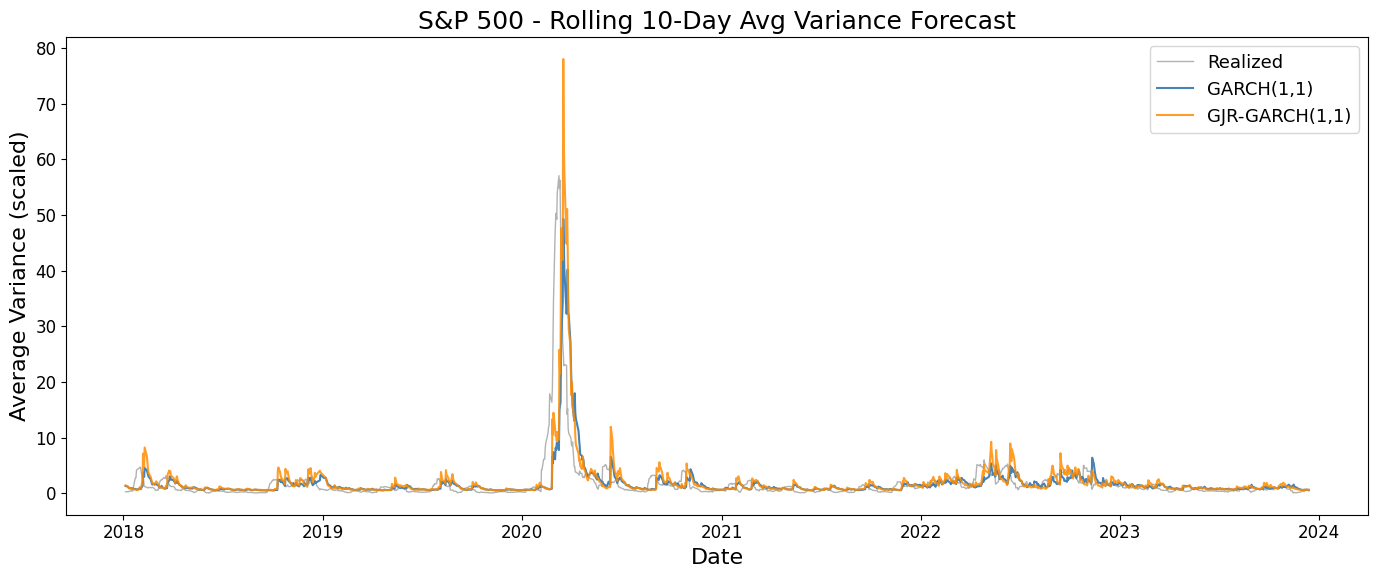

In [18]:
# Plot horserace for the most volatile index
fg, fj, real = horserace_results[mv]
valid = ~np.isnan(fg) & ~np.isnan(real)
idx = returns.index[:len(fg)]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(idx[valid], real[valid], color='grey', linewidth=1, alpha=0.6, label='Realized')
ax.plot(idx[valid], fg[valid], color='steelblue', linewidth=1.5, label='GARCH(1,1)')
ax.plot(idx[valid], fj[valid], color='darkorange', linewidth=1.5, label='GJR-GARCH(1,1)', alpha=0.85)
ax.set_title(f'{mv} - Rolling {T_horizon}-Day Avg Variance Forecast', fontsize=18)
ax.set_ylabel('Average Variance (scaled)')
ax.set_xlabel('Date')
ax.legend(fontsize=13)
fig.tight_layout()
fig.savefig(f'horserace_{mv.replace(" ", "_")}.png', dpi=200, bbox_inches='tight')
plt.show()

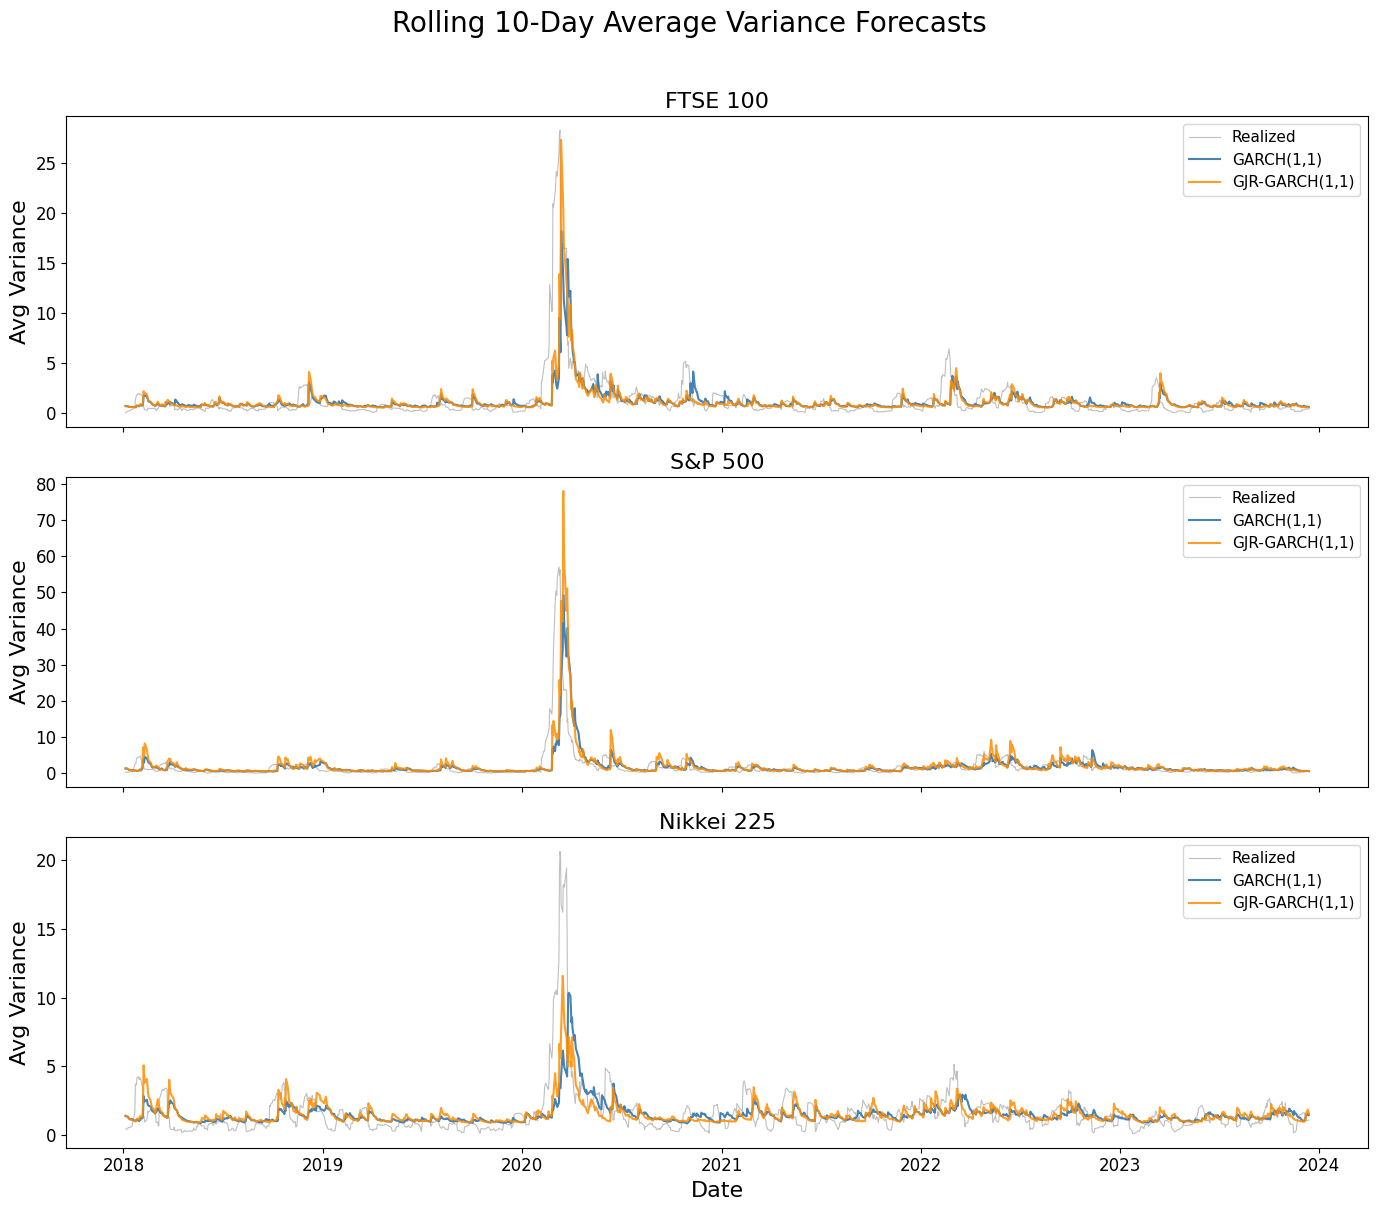

In [19]:
# Horserace plot for ALL indices side by side
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
for ax, col in zip(axes, returns.columns):
    fg, fj, real = horserace_results[col]
    valid = ~np.isnan(fg) & ~np.isnan(real)
    idx = returns.index[:len(fg)]
    
    ax.plot(idx[valid], real[valid], color='grey', linewidth=0.8, alpha=0.5, label='Realized')
    ax.plot(idx[valid], fg[valid], color='steelblue', linewidth=1.5, label='GARCH(1,1)')
    ax.plot(idx[valid], fj[valid], color='darkorange', linewidth=1.5, label='GJR-GARCH(1,1)', alpha=0.85)
    ax.set_title(f'{col}', fontsize=16)
    ax.set_ylabel('Avg Variance')
    ax.legend(fontsize=11, loc='upper right')

axes[-1].set_xlabel('Date')
fig.suptitle(f'Rolling {T_horizon}-Day Average Variance Forecasts', fontsize=20, y=1.01)
fig.tight_layout()
fig.savefig('horserace_all.png', dpi=200, bbox_inches='tight')
plt.show()

In [20]:
# Summary table for presentation
print("\n" + "="*70)
print("SUMMARY FOR PRESENTATION")
print("="*70)

print("\n--- GARCH(1,1) Parameters ---")
print(param_table[['omega','alpha[1]','beta[1]','alpha+beta','V_L_annual']].round(4))

print("\n--- GJR-GARCH(1,1) Parameters ---")
print(gjr_table[['omega','alpha[1]','gamma[1]','beta[1]']].round(4))

print("\n--- Information Criteria ---")
print(comp_df[['GARCH AIC','GJR AIC','GARCH BIC','GJR BIC']].round(2))

print("\n--- Forecast RMSE ---")
print(eval_df[['GARCH RMSE','GJR RMSE','Winner (RMSE)']].round(6))


SUMMARY FOR PRESENTATION

--- GARCH(1,1) Parameters ---
             omega  alpha[1]  beta[1]  alpha+beta  V_L_annual
FTSE 100    0.0779    0.1599   0.7696      0.9295      0.1668
S&P 500     0.0510    0.1721   0.8006      0.9727      0.2172
Nikkei 225  0.0629    0.0764   0.8805      0.9570      0.1919

--- GJR-GARCH(1,1) Parameters ---
             omega  alpha[1]  gamma[1]  beta[1]
FTSE 100    0.0717    0.0221    0.2124   0.8009
S&P 500     0.0598    0.0602    0.2859   0.7781
Nikkei 225  0.1017    0.0064    0.1856   0.8350

--- Information Criteria ---
            GARCH AIC  GJR AIC  GARCH BIC  GJR BIC
Index                                             
FTSE 100      3754.23  3719.29    3769.93  3740.23
S&P 500       4060.20  4008.71    4075.90  4029.65
Nikkei 225    4355.37  4310.29    4371.07  4331.23

--- Forecast RMSE ---
            GARCH RMSE  GJR RMSE Winner (RMSE)
Index                                         
FTSE 100      2.057503  1.879194           GJR
S&P 500       4.194